<div style="padding: 30px; background-color: #ffffff; border-radius: 15px; border: 1px solid #e1e4e8; box-shadow: 0 4px 6px rgba(0,0,0,0.1); margin-bottom: 30px; text-align: center;">
    <h1 style="color: #2c3e50; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin-bottom: 10px;">Análisis de Datos Profesional</h1>
    <p style="font-size: 1.2em; color: #7f8c8d; font-style: italic; margin-bottom: 20px;">Dominando DataFrames, Manipulaciones y Visualizaciones</p>
    <div style="width: 100%; height: 4px; background-color: #3498db; margin: 0 auto 20px;"></div>
    <p style="color: #34495e; font-weight: 500;">Tutorial Técnico y Reporte</p>
</div>

---

### 📌 Tabla de Contenidos


1. [Configuración del Entorno](#setup)
2. [Diagnóstico y Limpieza de Datos Inicial](#cleaning)
3. [Análisis Exploratorio de Datos (EDA)](#eda)
4. [Integración de Datos (Joins y Merges)](#merges)
5. [Visualizaciones e Insights](#visualization)

<a id='setup'></a>
## 🛠️ 1. Configuración del Entorno

Antes de comenzar con el análisis, nos aseguramos de importar todas las librerías necesarias y configurarlas para la visualización integrada.

In [1]:
#!pip install jupyter-black pandas seaborn matplotlib

In [2]:
%load_ext jupyter_black

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

# Configurar gráficos para que se muestren dentro del notebook
%matplotlib inline

# Verificar la versión de la librería
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de Pandas: {matplotlib.__version__}")
print(f"Versión de Pandas: {sns.__version__}")

Versión de Pandas: 3.0.3
Versión de Pandas: 3.11.0
Versión de Pandas: 0.13.2


<hr style="border: 0.5px solid #eee;">

<a id='cleaning'></a>
## 🧼 2. Diagnóstico y Limpieza de Datos Inicial

Antes de transformar o renombrar las columnas, realizaremos una auditoría rápida del archivo peru_df.csv para detectar

1. Valores nulos o faltantes.
2. Filas duplicadas.
3. Posibles anomalías en tipos de datos.

In [4]:
# Carga de datos
peru_df = pd.read_csv("peru.csv")
peru_df

,capital,pob,departamento,area km2,provincias,region,altitud (m),pibPerCapita,fecha
0,Chachapoyas,430.0,Amazonas,39249,7,Selva,2334,4200,01/15/24
1,Huaraz,NaN,Áncash,35825,20,Sierra,3052,7600,02/15/24
2,Abancay,428.0,Apurímac,20895,7,Sierra,2378,5200,03/01/24
3,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
4,Ayacucho,670.0,Ayacucho,43890,11,Sierra,2761,4500,05/12/24
5,Cajamarca,1451.0,Cajamarca,33317,13,Sierra,2750,4800,06/01/24
6,Callao,1191.0,Provincia Constitucional del Callao,146,1,Costa,5,10500,07/20/24
7,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24
8,Huancavelica,343.0,Huancavelica,22131,7,Sierra,3676,3800,09/01/24
9,Huanuco,751.0,Huánuco,36887,11,Sierra,1890,4300,10/05/24


In [5]:
# Identificar y mostrar errores o inconsistencias (Metadatos)
peru_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   capital       27 non-null     str    
 1   pob           23 non-null     float64
 2   departamento  27 non-null     str    
 3   area km2      27 non-null     int64  
 4   provincias    27 non-null     int64  
 5   region        27 non-null     str    
 6   altitud (m)   27 non-null     int64  
 7   pibPerCapita  27 non-null     int64  
 8   fecha         27 non-null     str    
dtypes: float64(1), int64(4), str(4)
memory usage: 2.8 KB


In [6]:
# Manejo de valores nulos (Faltantes)
valores_nulos = peru_df.isnull().sum()
valores_nulos

capital         0
pob             4
departamento    0
area km2        0
provincias      0
region          0
altitud (m)     0
pibPerCapita    0
fecha           0
dtype: int64

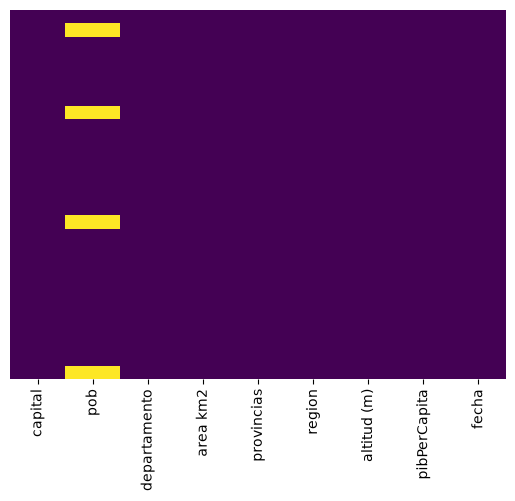

In [7]:
sns.heatmap(peru_df.isnull(), yticklabels=False, cbar=False, cmap="viridis")

plt.show()

In [8]:
# Mostrar de forma tabular cuáles filas contienen valores nulos en 'pob'
filas_con_nulos = peru_df[peru_df["pob"].isnull()]
filas_con_nulos

,capital,pob,departamento,area km2,provincias,region,altitud (m),pibPerCapita,fecha
1,Huaraz,NaN,Áncash,35825,20,Sierra,3052,7600,02/15/24
7,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24
15,Iquitos,NaN,Loreto,368852,8,Selva,104,5400,04/01/24
26,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24


In [9]:
# Mostrar filas duplicadas usando peru_df.duplicated()
filas_duplicadas = peru_df[peru_df.duplicated(keep=False)]
filas_duplicadas

,capital,pob,departamento,area km2,provincias,region,altitud (m),pibPerCapita,fecha
3,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
7,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24
25,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
26,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24


In [10]:
# Eliminar duplicados manteniendo la primera ocurrencia
peru_df = peru_df.drop_duplicates(keep="first")
peru_df

,capital,pob,departamento,area km2,provincias,region,altitud (m),pibPerCapita,fecha
0,Chachapoyas,430.0,Amazonas,39249,7,Selva,2334,4200,01/15/24
1,Huaraz,NaN,Áncash,35825,20,Sierra,3052,7600,02/15/24
2,Abancay,428.0,Apurímac,20895,7,Sierra,2378,5200,03/01/24
3,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
4,Ayacucho,670.0,Ayacucho,43890,11,Sierra,2761,4500,05/12/24
5,Cajamarca,1451.0,Cajamarca,33317,13,Sierra,2750,4800,06/01/24
6,Callao,1191.0,Provincia Constitucional del Callao,146,1,Costa,5,10500,07/20/24
7,Cusco,NaN,Cusco,71873,13,Sierra,3399,7200,08/15/24
8,Huancavelica,343.0,Huancavelica,22131,7,Sierra,3676,3800,09/01/24
9,Huanuco,751.0,Huánuco,36887,11,Sierra,1890,4300,10/05/24


In [11]:
# # Llenar valores en la columna 'pob' con la mediana
# peru_df = peru_df['pob'].fillna(peru_df['pob'].mean())

In [12]:
# Asignar valores de población nulos con datos reales y exactos usando .at
peru_df.at[1, "pob"] = 118
peru_df.at[7, "pob"] = 137
peru_df.at[15, "pob"] = 103
peru_df

,capital,pob,departamento,area km2,provincias,region,altitud (m),pibPerCapita,fecha
0,Chachapoyas,430.0,Amazonas,39249,7,Selva,2334,4200,01/15/24
1,Huaraz,118.0,Áncash,35825,20,Sierra,3052,7600,02/15/24
2,Abancay,428.0,Apurímac,20895,7,Sierra,2378,5200,03/01/24
3,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
4,Ayacucho,670.0,Ayacucho,43890,11,Sierra,2761,4500,05/12/24
5,Cajamarca,1451.0,Cajamarca,33317,13,Sierra,2750,4800,06/01/24
6,Callao,1191.0,Provincia Constitucional del Callao,146,1,Costa,5,10500,07/20/24
7,Cusco,137.0,Cusco,71873,13,Sierra,3399,7200,08/15/24
8,Huancavelica,343.0,Huancavelica,22131,7,Sierra,3676,3800,09/01/24
9,Huanuco,751.0,Huánuco,36887,11,Sierra,1890,4300,10/05/24


In [13]:
# Renombrado profesional de columnas
peru_df = peru_df.rename(
    columns={
        "capital": "CAPITAL",
        "pob": "POBLACION (millones)",
        "departamento": "DEPARTAMENTO",
        "area km2": "SUPERFICIE (km²)",
        "provincias": "PROVINCIAS",
        "region": "REGION",
        "altitud (m)": "ALTITUD (msnm)",
        "pibPerCapita": "PIB",
        "fecha": "FECHA",
    }
)
peru_df

,CAPITAL,POBLACION (millones),DEPARTAMENTO,SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA
0,Chachapoyas,430.0,Amazonas,39249,7,Selva,2334,4200,01/15/24
1,Huaraz,118.0,Áncash,35825,20,Sierra,3052,7600,02/15/24
2,Abancay,428.0,Apurímac,20895,7,Sierra,2378,5200,03/01/24
3,Arequipa,1580.0,Arequipa,63345,8,Costa,2335,8800,04/10/24
4,Ayacucho,670.0,Ayacucho,43890,11,Sierra,2761,4500,05/12/24
5,Cajamarca,1451.0,Cajamarca,33317,13,Sierra,2750,4800,06/01/24
6,Callao,1191.0,Provincia Constitucional del Callao,146,1,Costa,5,10500,07/20/24
7,Cusco,137.0,Cusco,71873,13,Sierra,3399,7200,08/15/24
8,Huancavelica,343.0,Huancavelica,22131,7,Sierra,3676,3800,09/01/24
9,Huanuco,751.0,Huánuco,36887,11,Sierra,1890,4300,10/05/24


In [14]:
# Establecer un índice significativo
peru_df = peru_df.set_index("DEPARTAMENTO")
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA
DEPARTAMENTO,,,,,,,,
Amazonas,Chachapoyas,430.0,39249,7,Selva,2334,4200,01/15/24
Áncash,Huaraz,118.0,35825,20,Sierra,3052,7600,02/15/24
Apurímac,Abancay,428.0,20895,7,Sierra,2378,5200,03/01/24
Arequipa,Arequipa,1580.0,63345,8,Costa,2335,8800,04/10/24
Ayacucho,Ayacucho,670.0,43890,11,Sierra,2761,4500,05/12/24
Cajamarca,Cajamarca,1451.0,33317,13,Sierra,2750,4800,06/01/24
Provincia Constitucional del Callao,Callao,1191.0,146,1,Costa,5,10500,07/20/24
Cusco,Cusco,137.0,71873,13,Sierra,3399,7200,08/15/24
Huancavelica,Huancavelica,343.0,22131,7,Sierra,3676,3800,09/01/24


In [15]:
# Convertir la columna FECHA a datetime
peru_df["FECHA"] = pd.to_datetime(peru_df["FECHA"], format="%m/%d/%y")
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA
DEPARTAMENTO,,,,,,,,
Amazonas,Chachapoyas,430.0,39249,7,Selva,2334,4200,2024-01-15
Áncash,Huaraz,118.0,35825,20,Sierra,3052,7600,2024-02-15
Apurímac,Abancay,428.0,20895,7,Sierra,2378,5200,2024-03-01
Arequipa,Arequipa,1580.0,63345,8,Costa,2335,8800,2024-04-10
Ayacucho,Ayacucho,670.0,43890,11,Sierra,2761,4500,2024-05-12
Cajamarca,Cajamarca,1451.0,33317,13,Sierra,2750,4800,2024-06-01
Provincia Constitucional del Callao,Callao,1191.0,146,1,Costa,5,10500,2024-07-20
Cusco,Cusco,137.0,71873,13,Sierra,3399,7200,2024-08-15
Huancavelica,Huancavelica,343.0,22131,7,Sierra,3676,3800,2024-09-01


<hr style="border: 0.5px solid #eee;">

<a id='eda'></a>
## 📊 3. Análisis Exploratorio de Datos (EDA)
Comprender la distribución y las características de nuestros datos utilizando resúmenes estadísticos y muestreo aleatorio.

In [16]:
# Estadísticas descriptivas
peru_df.describe()

,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,ALTITUD (msnm),PIB,FECHA
count,25.00000,25.000000,25.000000,25.000000,25.000000,25
mean,1217.64000,51438.360000,7.840000,1596.800000,6700.000000,2024-07-04 00:00:00
min,103.00000,146.000000,1.000000,5.000000,3800.000000,2024-01-15 00:00:00
25%,267.00000,21328.000000,4.000000,154.000000,4800.000000,2024-04-01 00:00:00
50%,670.00000,35733.000000,8.000000,1410.000000,6200.000000,2024-07-04 00:00:00
75%,1351.00000,51842.000000,11.000000,2761.000000,7600.000000,2024-10-01 00:00:00
max,11148.00000,368852.000000,20.000000,4330.000000,14200.000000,2024-12-31 00:00:00
std,2156.88985,70655.265313,4.469154,1488.992445,2542.636427,NaN


### Generacion de columnas a partir de otras

Extraer el nombre del día en español

In [17]:
# Extraer el nombre del día en inglés
peru_df["DIA SEMANA ENG"] = peru_df["FECHA"].dt.day_name()

# Mapear los nombres de días a español
mapeo_dias = {
    "Monday": "Lunes",
    "Tuesday": "Martes",
    "Wednesday": "Miércoles",
    "Thursday": "Jueves",
    "Friday": "Viernes",
    "Saturday": "Sábado",
    "Sunday": "Domingo",
}

peru_df["DIA SEMANA"] = peru_df["DIA SEMANA ENG"].map(mapeo_dias)
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA ENG,DIA SEMANA
DEPARTAMENTO,,,,,,,,,,
Amazonas,Chachapoyas,430.0,39249,7,Selva,2334,4200,2024-01-15,Monday,Lunes
Áncash,Huaraz,118.0,35825,20,Sierra,3052,7600,2024-02-15,Thursday,Jueves
Apurímac,Abancay,428.0,20895,7,Sierra,2378,5200,2024-03-01,Friday,Viernes
Arequipa,Arequipa,1580.0,63345,8,Costa,2335,8800,2024-04-10,Wednesday,Miércoles
Ayacucho,Ayacucho,670.0,43890,11,Sierra,2761,4500,2024-05-12,Sunday,Domingo
Cajamarca,Cajamarca,1451.0,33317,13,Sierra,2750,4800,2024-06-01,Saturday,Sábado
Provincia Constitucional del Callao,Callao,1191.0,146,1,Costa,5,10500,2024-07-20,Saturday,Sábado
Cusco,Cusco,137.0,71873,13,Sierra,3399,7200,2024-08-15,Thursday,Jueves
Huancavelica,Huancavelica,343.0,22131,7,Sierra,3676,3800,2024-09-01,Sunday,Domingo


### Eliminar

Eliminar columnas o indexes (Los parámetros `index` y `columns` son más modernos y claros que usar `axis`.)

In [18]:
# Eliminar la columna
peru_df = peru_df.drop(columns=["DIA SEMANA ENG"], axis=0)

In [19]:
# # Eliminar filas y resetear índices
# peru_df = peru_df.drop(index=[1, 7])
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA
DEPARTAMENTO,,,,,,,,,
Amazonas,Chachapoyas,430.0,39249,7,Selva,2334,4200,2024-01-15,Lunes
Áncash,Huaraz,118.0,35825,20,Sierra,3052,7600,2024-02-15,Jueves
Apurímac,Abancay,428.0,20895,7,Sierra,2378,5200,2024-03-01,Viernes
Arequipa,Arequipa,1580.0,63345,8,Costa,2335,8800,2024-04-10,Miércoles
Ayacucho,Ayacucho,670.0,43890,11,Sierra,2761,4500,2024-05-12,Domingo
Cajamarca,Cajamarca,1451.0,33317,13,Sierra,2750,4800,2024-06-01,Sábado
Provincia Constitucional del Callao,Callao,1191.0,146,1,Costa,5,10500,2024-07-20,Sábado
Cusco,Cusco,137.0,71873,13,Sierra,3399,7200,2024-08-15,Jueves
Huancavelica,Huancavelica,343.0,22131,7,Sierra,3676,3800,2024-09-01,Domingo


### Ingeniería de Características Personalizada

In [20]:
# Normalización de datos de población (asumiendo que están en miles)
peru_df["POBLACION (millones)"] = peru_df["POBLACION (millones)"] / 1000
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA
DEPARTAMENTO,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado
Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo


In [21]:
# Cálculo de la Densidad Poblacional
peru_df["DENSIDAD (hab/km²)"] = (peru_df["POBLACION (millones)"] * 1_000_000) / peru_df[
    "SUPERFICIE (km²)"
]
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²)
DEPARTAMENTO,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340
Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622


In [22]:
# Categorización de departamentos basada en su desempeño económico utilizando el método `.apply()`.
def segmentar_pib(valor):
    """Clasifica el desempeño económico basado en el PIB per cápita."""
    if valor > 9000:
        return "Alto"
    elif 5000 <= valor <= 9000:
        return "Medio"
    else:
        return "Bajo"


peru_df["NIVEL ECONOMICO"] = peru_df["PIB"].apply(segmentar_pib)
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247,Alto
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo


### Selección de Columnas e Indexación

Recuperación de dimensiones específicas de nuestro conjunto de datos para un análisis enfocado.

In [23]:
# Selección de atributos específicos
subset = peru_df[["CAPITAL", "ALTITUD (msnm)", "REGION"]]
subset

,CAPITAL,ALTITUD (msnm),REGION
DEPARTAMENTO,,,
Amazonas,Chachapoyas,2334,Selva
Áncash,Huaraz,3052,Sierra
Apurímac,Abancay,2378,Sierra
Arequipa,Arequipa,2335,Costa
Ayacucho,Ayacucho,2761,Sierra
Cajamarca,Cajamarca,2750,Sierra
Provincia Constitucional del Callao,Callao,5,Costa
Cusco,Cusco,3399,Sierra
Huancavelica,Huancavelica,3676,Sierra


In [24]:
# Selección por etiqueta
peru_df.loc[["Cusco", "Arequipa", "Lima"], ["POBLACION (millones)", "REGION"]]

,POBLACION (millones),REGION
DEPARTAMENTO,,
Cusco,0.137,Sierra
Arequipa,1.580,Costa
Lima,11.148,Costa


In [25]:
# Selección por posición
peru_df.iloc[[7, 3, 14], [1, 4]]

,POBLACION (millones),REGION
DEPARTAMENTO,,
Cusco,0.137,Sierra
Arequipa,1.580,Costa
Lima,11.148,Costa


### Formas de Filtrar
Filtrado del conjunto de datos

In [26]:
# Filtro: Población < 0.5 Millones
peru_df[peru_df["POBLACION (millones)"] < 0.5]
peru_df

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247,Alto
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo


In [27]:
# Filtro: Región Sierra
peru_df[peru_df["REGION"] == "Sierra"]

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo
Huánuco,Huanuco,0.751,36887,11,Sierra,1890,4300,2024-10-05,Sábado,20.359476,Bajo
Junín,Huancayo,1.378,44410,9,Sierra,3250,6500,2024-12-01,Domingo,31.029048,Medio
Pasco,Cerro de Pasco,0.267,25319,3,Sierra,4330,5800,2024-07-04,Jueves,10.545440,Medio


In [28]:
# loc con máscara (control sobre columnas)
peru_df.loc[peru_df["POBLACION (millones)"] < 0.5, ["CAPITAL", "REGION"]]

,CAPITAL,REGION
DEPARTAMENTO,,
Amazonas,Chachapoyas,Selva
Áncash,Huaraz,Sierra
Apurímac,Abancay,Sierra
Cusco,Cusco,Sierra
Huancavelica,Huancavelica,Sierra
Loreto,Iquitos,Selva
Madre de Dios,Puerto Maldonado,Selva
Moquegua,Moquegua,Costa
Pasco,Cerro de Pasco,Sierra


In [29]:
# isin() — varios valores a la vez
peru_df[peru_df["REGION"].isin(["Sierra", "Selva"])]

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo
Huánuco,Huanuco,0.751,36887,11,Sierra,1890,4300,2024-10-05,Sábado,20.359476,Bajo
Junín,Huancayo,1.378,44410,9,Sierra,3250,6500,2024-12-01,Domingo,31.029048,Medio


In [30]:
# between() — rangos inclusivos
peru_df[peru_df["POBLACION (millones)"].between(0.2, 0.5)]

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo
Pasco,Cerro de Pasco,0.267,25319,3,Sierra,4330,5800,2024-07-04,Jueves,10.545440,Medio
Tacna,Tacna,0.390,16075,4,Costa,562,9000,2024-11-20,Miércoles,24.261275,Medio
Tumbes,Tumbes,0.263,4669,3,Costa,7,5300,2024-12-05,Jueves,56.328978,Medio


In [31]:
# str.contains() — filtro por texto parcial
peru_df[peru_df["CAPITAL"].str.contains("chapo", case=False)]

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.43,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo


### Agrupaciones y Agregaciones
Resumen de datos a nivel regional para revelar patrones macroeconómicos.

In [32]:
# Agregación de población por región y nivel económico
resumen = peru_df.groupby(by="REGION")["POBLACION (millones)"].sum()
resumen

REGION
Costa     21.394
Selva      2.286
Sierra     6.761
Name: POBLACION (millones), dtype: float64

### Ordenamiento y Creación de Atributos
Cálculo de la densidad poblacional y ordenamiento de los resultados para identificar valores atípicos clave.

In [33]:
# Ordenar por población
peru_df.sort_values(by="POBLACION (millones)", ascending=False)

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Lima,Lima,11.148,34801,10,Costa,154,14200,2024-03-30,Sábado,320.335623,Alto
Piura,Piura,2.127,35733,8,Costa,29,6200,2024-08-15,Jueves,59.524809,Medio
La Libertad,Trujillo,2.104,25699,12,Costa,34,7000,2024-01-18,Jueves,81.870890,Medio
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Junín,Huancayo,1.378,44410,9,Sierra,3250,6500,2024-12-01,Domingo,31.029048,Medio
Lambayeque,Chiclayo,1.351,14231,3,Costa,27,6200,2024-02-20,Martes,94.933596,Medio
Puno,Puno,1.218,71999,13,Sierra,3827,4200,2024-09-12,Jueves,16.916902,Bajo
Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247,Alto


In [34]:
# Ordenar por index
peru_df.sort_index(axis=0)

,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
DEPARTAMENTO,,,,,,,,,,,
Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio
Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo
Huánuco,Huanuco,0.751,36887,11,Sierra,1890,4300,2024-10-05,Sábado,20.359476,Bajo
Ica,Ica,1.041,21328,5,Costa,406,9200,2024-11-11,Lunes,48.809077,Alto


### Multi-Agregación
Aplicación de múltiples funciones estadísticas simultáneamente para explorar los límites de los datos.

In [35]:
# Estadísticas en lote
peru_df[["POBLACION (millones)", "PIB"]].agg(["min", "max", "mean"])

,POBLACION (millones),PIB
min,0.10300,3800.0
max,11.14800,14200.0
mean,1.21764,6700.0


In [36]:
# Segmentación avanzada de información por REGION
segmentacion_region = peru_df.groupby("REGION").agg(
    {
        "POBLACION (millones)": ["mean", "sum", "std"],
        "PIB": ["mean", "max"],
        "ALTITUD (msnm)": "mean",
    }
)
segmentacion_region

POBLACION (millones)                       PIB        ALTITUD (msnm)
                       mean     sum       std    mean    max           mean
REGION                                                                     
Costa                2.1394  21.394  3.241110  8740.0  14200          496.9
Selva                0.4572   2.286  0.336966  5240.0   6800          727.6
Sierra               0.6761   6.761  0.509293  5390.0   7600         3131.3

In [37]:
# Ejemplo de funciones de agregación pero  personalizadas
def promedio_con_constante(columna, k=1.2):
    # Multiplicamos cada elemento por k, y al resultado le sacamos el promedio
    return (columna * k).mean()


agg_personalizado = peru_df[["POBLACION (millones)", "PIB"]].agg(
    promedio_con_constante, k=1.5
)
agg_personalizado

POBLACION (millones)        1.82646
PIB                     10050.00000
dtype: float64

### Análisis de Correlación

Un análisis de correlación es una herramienta estadística que nos permite medir la fuerza y la dirección de la relación lineal entre dos variables numéricas sin asumir necesariamente que una causa a la otra.

In [38]:
# Definir la lista de columnas estrictamente numéricas seleccionadas
columnas_numericas = [
    "POBLACION (millones)",
    "SUPERFICIE (km²)",
    "PROVINCIAS",
    "ALTITUD (msnm)",
    "PIB",
    "DENSIDAD (hab/km²)",
]

# Filtrar el DataFrame
peru_numerico_filtrado = peru_df[columnas_numericas]

# 3. Calcular la matriz de correlación de Pearson
matriz_correlacion = peru_numerico_filtrado.corr(method="pearson")
matriz_correlacion

,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,ALTITUD (msnm),PIB,DENSIDAD (hab/km²)
POBLACION (millones),1.000000,-0.114813,0.131644,-0.252884,0.602537,0.035055
SUPERFICIE (km²),-0.114813,1.000000,0.097241,-0.140621,-0.187978,-0.158789
PROVINCIAS,0.131644,0.097241,1.000000,0.438005,-0.171236,-0.317589
ALTITUD (msnm),-0.252884,-0.140621,0.438005,1.000000,-0.363365,-0.236684
PIB,0.602537,-0.187978,-0.171236,-0.363365,1.000000,0.334714
DENSIDAD (hab/km²),0.035055,-0.158789,-0.317589,-0.236684,0.334714,1.000000


In [39]:
from scipy import stats

# 2. Pruebas de hipótesis (t-test para dos muestras independientes)
# Hipótesis Nula (H0): El PIB promedio de la Costa y de la Sierra es igual.
# Hipótesis Alternativa (H1): El PIB promedio de la Costa y de la Sierra es diferente.

# Filtrar muestras válidas quitando nulos si existieran
pib_costa = peru_df[peru_df["REGION"] == "Costa"]["PIB"].dropna()
pib_sierra = peru_df[peru_df["REGION"] == "Sierra"]["PIB"].dropna()

t_stat, p_val = stats.ttest_ind(pib_costa, pib_sierra, equal_var=False)

print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p (p-value): {p_val:.6f}")

if p_val < 0.05:
    print(
        "Rechazamos la hipótesis nula (H0). Existe una diferencia estadísticamente significativa entre el PIB de la Costa y la Sierra."
    )
else:
    print(
        "No se puede rechazar la hipótesis nula (H0). No hay evidencia suficiente para afirmar que los PIB promedio sean distintos."
    )

Estadístico t: 3.5110
Valor p (p-value): 0.003796
Rechazamos la hipótesis nula (H0). Existe una diferencia estadísticamente significativa entre el PIB de la Costa y la Sierra.


<a id='integracion'></a>
## 🛠️ 4. Integración de Datos (Joins y Merges)

Combinación de nuestro conjunto de datos primario con datos de proyectos auxiliares utilizando diferentes estrategias de unión.

In [40]:
peru_df = peru_df.reset_index()
peru_df

,DEPARTAMENTO,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO
0,Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo
1,Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio
2,Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio
3,Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio
4,Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo
5,Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo
6,Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247,Alto
7,Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio
8,Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo
9,Huánuco,Huanuco,0.751,36887,11,Sierra,1890,4300,2024-10-05,Sábado,20.359476,Bajo


In [41]:
# Conjunto de datos de proyectos auxiliares
data_proyectos = {
    "DEPARTAMENTO": ["Arequipa", "Lima", "Cusco", "Piura", "Loreto", "Extranjero"],
    "INVERSION (millones)": [1500, 4200, 850, 600, 300, 5000],
    "TIPO_PRO": [
        "Minería",
        "Transporte",
        "Energía",
        "Agricultura",
        "Ambiental",
        "Comercio",
    ],
    "ESTADO": [
        "Ejecución",
        "Planificación",
        "Ejecución",
        "Finalizado",
        "Suspendido",
        "Nuevo",
    ],
}
proyectos_df = pd.DataFrame(data_proyectos)
proyectos_df

,DEPARTAMENTO,INVERSION (millones),TIPO_PRO,ESTADO
0,Arequipa,1500,Minería,Ejecución
1,Lima,4200,Transporte,Planificación
2,Cusco,850,Energía,Ejecución
3,Piura,600,Agricultura,Finalizado
4,Loreto,300,Ambiental,Suspendido
5,Extranjero,5000,Comercio,Nuevo


### Comparación de Tipos de Join
Visualización de cómo las diferentes estrategias de unión afectan el resultado.

In [42]:
# Inner Join: Solo registros comunes
inner_df = pd.merge(peru_df, proyectos_df, on="DEPARTAMENTO", how="inner")
inner_df

,DEPARTAMENTO,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO,INVERSION (millones),TIPO_PRO,ESTADO
0,Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio,1500,Minería,Ejecución
1,Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio,850,Energía,Ejecución
2,Lima,Lima,11.148,34801,10,Costa,154,14200,2024-03-30,Sábado,320.335623,Alto,4200,Transporte,Planificación
3,Loreto,Iquitos,0.103,368852,8,Selva,104,5400,2024-04-01,Lunes,0.279245,Medio,300,Ambiental,Suspendido
4,Piura,Piura,2.127,35733,8,Costa,29,6200,2024-08-15,Jueves,59.524809,Medio,600,Agricultura,Finalizado


In [43]:
# Left Join: Preservar todos los datos primarios
left_df = pd.merge(peru_df.reset_index(), proyectos_df, on="DEPARTAMENTO", how="left")
left_df

,index,DEPARTAMENTO,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO,INVERSION (millones),TIPO_PRO,ESTADO
0,0,Amazonas,Chachapoyas,0.430,39249,7,Selva,2334,4200,2024-01-15,Lunes,10.955693,Bajo,NaN,NaN,NaN
1,1,Áncash,Huaraz,0.118,35825,20,Sierra,3052,7600,2024-02-15,Jueves,3.293789,Medio,NaN,NaN,NaN
2,2,Apurímac,Abancay,0.428,20895,7,Sierra,2378,5200,2024-03-01,Viernes,20.483369,Medio,NaN,NaN,NaN
3,3,Arequipa,Arequipa,1.580,63345,8,Costa,2335,8800,2024-04-10,Miércoles,24.942774,Medio,1500.0,Minería,Ejecución
4,4,Ayacucho,Ayacucho,0.670,43890,11,Sierra,2761,4500,2024-05-12,Domingo,15.265436,Bajo,NaN,NaN,NaN
5,5,Cajamarca,Cajamarca,1.451,33317,13,Sierra,2750,4800,2024-06-01,Sábado,43.551340,Bajo,NaN,NaN,NaN
6,6,Provincia Constitucional del Callao,Callao,1.191,146,1,Costa,5,10500,2024-07-20,Sábado,8157.534247,Alto,NaN,NaN,NaN
7,7,Cusco,Cusco,0.137,71873,13,Sierra,3399,7200,2024-08-15,Jueves,1.906140,Medio,850.0,Energía,Ejecución
8,8,Huancavelica,Huancavelica,0.343,22131,7,Sierra,3676,3800,2024-09-01,Domingo,15.498622,Bajo,NaN,NaN,NaN
9,9,Huánuco,Huanuco,0.751,36887,11,Sierra,1890,4300,2024-10-05,Sábado,20.359476,Bajo,NaN,NaN,NaN


In [44]:
# Right Join: Enfocado en los datos de proyectos auxiliares
right_df = pd.merge(peru_df, proyectos_df, on="DEPARTAMENTO", how="right")
right_df

,DEPARTAMENTO,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO,INVERSION (millones),TIPO_PRO,ESTADO
0,Arequipa,Arequipa,1.580,63345.0,8.0,Costa,2335.0,8800.0,2024-04-10,Miércoles,24.942774,Medio,1500,Minería,Ejecución
1,Lima,Lima,11.148,34801.0,10.0,Costa,154.0,14200.0,2024-03-30,Sábado,320.335623,Alto,4200,Transporte,Planificación
2,Cusco,Cusco,0.137,71873.0,13.0,Sierra,3399.0,7200.0,2024-08-15,Jueves,1.906140,Medio,850,Energía,Ejecución
3,Piura,Piura,2.127,35733.0,8.0,Costa,29.0,6200.0,2024-08-15,Jueves,59.524809,Medio,600,Agricultura,Finalizado
4,Loreto,Iquitos,0.103,368852.0,8.0,Selva,104.0,5400.0,2024-04-01,Lunes,0.279245,Medio,300,Ambiental,Suspendido
5,Extranjero,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,5000,Comercio,Nuevo


In [45]:
# Outer Join: Unión completa de ambos conjuntos de datos
outer_df = pd.merge(peru_df, proyectos_df, on="DEPARTAMENTO", how="outer")
outer_df

,DEPARTAMENTO,CAPITAL,POBLACION (millones),SUPERFICIE (km²),PROVINCIAS,REGION,ALTITUD (msnm),PIB,FECHA,DIA SEMANA,DENSIDAD (hab/km²),NIVEL ECONOMICO,INVERSION (millones),TIPO_PRO,ESTADO
0,Amazonas,Chachapoyas,0.430,39249.0,7.0,Selva,2334.0,4200.0,2024-01-15,Lunes,10.955693,Bajo,NaN,NaN,NaN
1,Apurímac,Abancay,0.428,20895.0,7.0,Sierra,2378.0,5200.0,2024-03-01,Viernes,20.483369,Medio,NaN,NaN,NaN
2,Arequipa,Arequipa,1.580,63345.0,8.0,Costa,2335.0,8800.0,2024-04-10,Miércoles,24.942774,Medio,1500.0,Minería,Ejecución
3,Ayacucho,Ayacucho,0.670,43890.0,11.0,Sierra,2761.0,4500.0,2024-05-12,Domingo,15.265436,Bajo,NaN,NaN,NaN
4,Cajamarca,Cajamarca,1.451,33317.0,13.0,Sierra,2750.0,4800.0,2024-06-01,Sábado,43.551340,Bajo,NaN,NaN,NaN
5,Cusco,Cusco,0.137,71873.0,13.0,Sierra,3399.0,7200.0,2024-08-15,Jueves,1.906140,Medio,850.0,Energía,Ejecución
6,Extranjero,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,5000.0,Comercio,Nuevo
7,Huancavelica,Huancavelica,0.343,22131.0,7.0,Sierra,3676.0,3800.0,2024-09-01,Domingo,15.498622,Bajo,NaN,NaN,NaN
8,Huánuco,Huanuco,0.751,36887.0,11.0,Sierra,1890.0,4300.0,2024-10-05,Sábado,20.359476,Bajo,NaN,NaN,NaN
9,Ica,Ica,1.041,21328.0,5.0,Costa,406.0,9200.0,2024-11-11,Lunes,48.809077,Alto,NaN,NaN,NaN


### Concatenación Vertical y Horizontal
Unión de DataFrames a lo largo de un eje sin utilizar claves.

In [46]:
# Concatenación horizontal (Añadir columnas)
data_encargados = {
    "RESPONSABLE": [
        "Ing. García",
        "Dra. López",
        "Ing. Torres",
        "Lic. Ruiz",
        "Ing. Salas",
        "Eco. Benites",
    ],
    "FECHA_INICIO": ["2024-01", "2023-11", "2024-03", "2023-06", "2024-05", "2024-08"],
}
encargados_df = pd.DataFrame(data_encargados)
proyectos_extendido = pd.concat([proyectos_df, encargados_df], axis=1)
proyectos_extendido

,DEPARTAMENTO,INVERSION (millones),TIPO_PRO,ESTADO,RESPONSABLE,FECHA_INICIO
0,Arequipa,1500,Minería,Ejecución,Ing. García,2024-01
1,Lima,4200,Transporte,Planificación,Dra. López,2023-11
2,Cusco,850,Energía,Ejecución,Ing. Torres,2024-03
3,Piura,600,Agricultura,Finalizado,Lic. Ruiz,2023-06
4,Loreto,300,Ambiental,Suspendido,Ing. Salas,2024-05
5,Extranjero,5000,Comercio,Nuevo,Eco. Benites,2024-08


In [47]:
# Concatenación vertical (Añadir filas)
data_nuevos = {"DEPARTAMENTO": ["Tacna", "Puno"], "INVERSION (millones)": [450, 920]}
nuevos_df = pd.DataFrame(data_nuevos)
proyectos_final = pd.concat([proyectos_df, nuevos_df], axis=0).reset_index(drop=True)
proyectos_final

,DEPARTAMENTO,INVERSION (millones),TIPO_PRO,ESTADO
0,Arequipa,1500,Minería,Ejecución
1,Lima,4200,Transporte,Planificación
2,Cusco,850,Energía,Ejecución
3,Piura,600,Agricultura,Finalizado
4,Loreto,300,Ambiental,Suspendido
5,Extranjero,5000,Comercio,Nuevo
6,Tacna,450,NaN,NaN
7,Puno,920,NaN,NaN


### Exportación de Datos
Garantizar la interoperabilidad guardando los datos procesados en varios formatos profesionales.

In [48]:
# Exportación a múltiples formatos
peru_df.to_excel("peru_df_final.xlsx")
peru_df.to_csv("peru_df_final.csv", encoding="UTF-8")
peru_df.to_json("peru_df_final.json", orient="records", indent=4, date_format="iso")
peru_df.to_html("peru_df_final.html")

print("¡Todos los archivos se exportaron exitosamente!")

¡Todos los archivos se exportaron exitosamente!


<hr style="border: 0.5px solid #eee;">

<a id='visualization'></a>
## 🖼️ 5. Visualizaciones e Insights
Comunicación de tendencias de datos a través de visualizaciones potentes pero limpias.

### Visualización y Comunicación de Datos

¡Perfecto! Esta unidad cubre la visualización y comunicación de datos. Te proporciono una guía completa y práctica.

## 1. Principios de Visualización

**Principios Clave:**
- **Claridad**: La visualización debe comunicar información de forma clara
- **Precisión**: Los datos deben representarse con exactitud sin distorsión
- **Eficiencia**: Transmitir máxima información con mínima complejidad
- **Estética**: Visualmente atractivo pero sin sacrificar la claridad

**Paquetes de Python recomendados:**
- **Matplotlib**: Librería base para gráficos
- **Seaborn**: Visualizaciones estadísticas con mejor estética
- **Plotly**: Visualizaciones interactivas
- **Pandas**: Capacidades de graficación integradas

## 2. Buenas Prácticas de Diseño

**Mejores Prácticas:**
- Usar esquemas de colores apropiados (considerar paletas amigables para daltónicos)
- Incluir títulos, etiquetas y leyendas claras
- Evitar elementos innecesarios (decoraciones que no aportan)
- Mantener escalas y proporciones consistentes
- Usar espacios en blanco efectivamente
- Elegir fuentes y tamaños legibles
- Agregar contexto con anotaciones cuando sea necesario

## 3. Selección de Gráficos según el Tipo de Análisis

**Tipos de Gráficos Comunes:**

- **Comparación**: Gráficos de barras, columnas
- **Distribución**: Histogramas, diagramas de caja, gráficos de violín
- **Relación/Correlación**: Gráficos de dispersión, mapas de calor
- **Composición**: Gráficos circulares, barras apiladas, treemaps
- **Tendencia temporal**: Gráficos de líneas, áreas
- **Geoespacial**: Mapas, mapas coropléticos

**Para tu dataset `peru_df`, podrías crear:**
- Gráfico de barras: Comparar población o PIB per cápita por departamento
- Gráfico de dispersión: Relación entre altitud y PIB per cápita
- Histograma: Distribución de área o población
- Diagrama de caja: Comparar PIB per cápita entre regiones (Sierra, Selva, Costa)

### **GRÁFICO 1: Top 10 Departamentos por PIB**

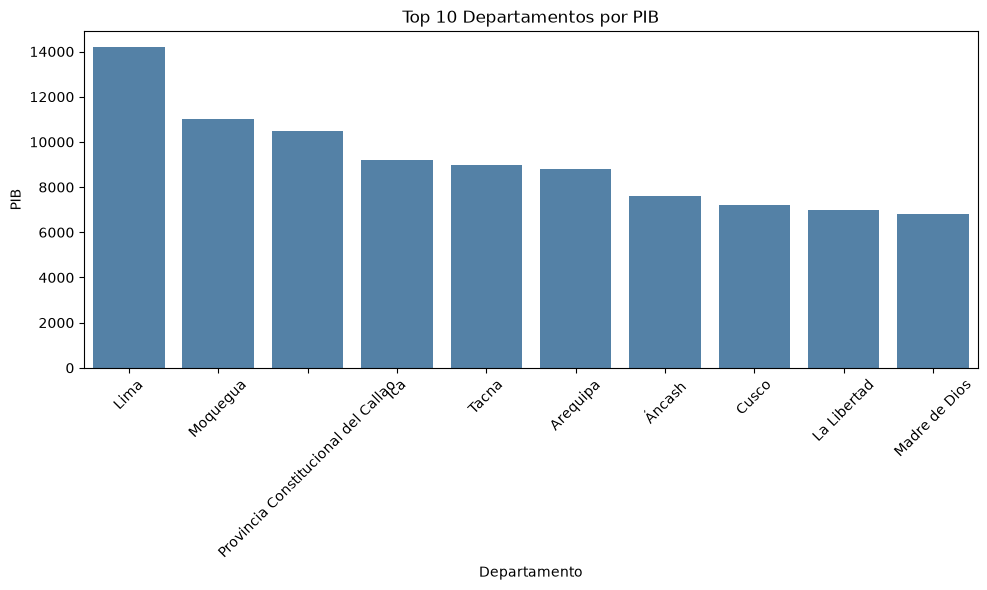

In [49]:
# 1. Gráfico de barras: PIB por departamento (top 10)
top_10_pib = peru_df.nlargest(10, "PIB")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_10_pib, x="DEPARTAMENTO", y="PIB", color="steelblue")
plt.title("Top 10 Departamentos por PIB")
plt.xlabel("Departamento")
plt.ylabel("PIB")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**📊 INTERPRETACIÓN DE RESULTADOS:**
- Se observa una clara concentración económica en pocos departamentos del país
- El departamento líder tiene un PIB significativamente superior al resto
- Existe una brecha considerable entre el primer y décimo lugar
- La distribución muestra una curva descendente pronunciada

**💡 COMUNICACIÓN DE HALLAZGOS:**
- **Desigualdad económica regional**: Los 10 departamentos con mayor PIB concentran la mayor parte de la actividad económica del país, dejando a los demás en situación de menor desarrollo
- **Centralización económica**: Los departamentos líderes probablemente albergan las principales ciudades, puertos, industrias y centros comerciales
- **Implicaciones**: Esta concentración puede generar migración interna, presión sobre servicios urbanos y perpetuar la desigualdad regional
- **Recomendación**: Se requieren políticas de descentralización y promoción del desarrollo en departamentos con menor PIB

### **GRÁFICO 2: Relación entre Altitud y PIB**

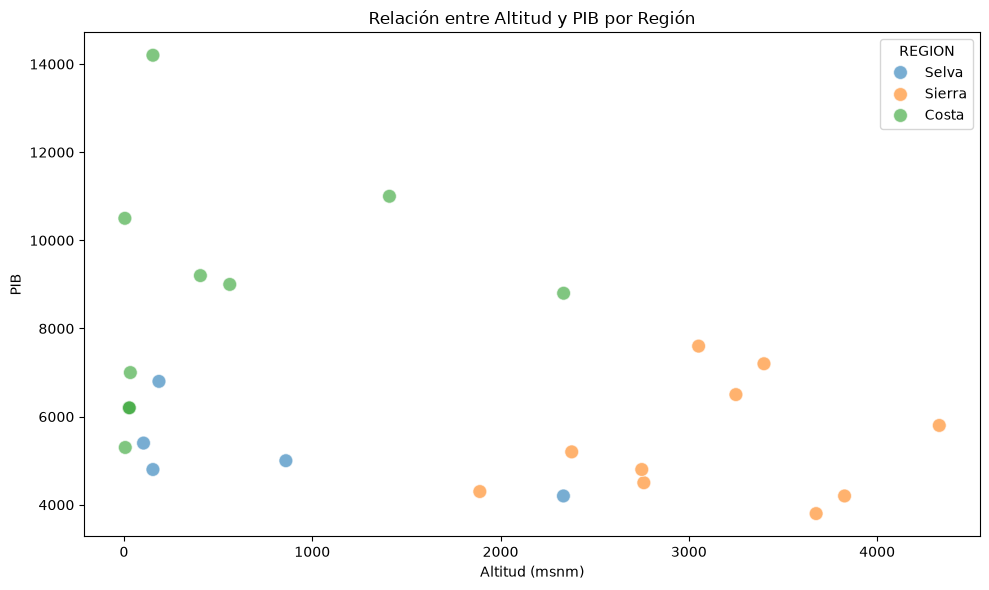

In [50]:
# 2. Gráfico de dispersión: Altitud vs PIB
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=peru_df, x="ALTITUD (msnm)", y="PIB", hue="REGION", alpha=0.6, s=100
)
plt.title("Relación entre Altitud y PIB por Región")
plt.xlabel("Altitud (msnm)")
plt.ylabel("PIB")
plt.tight_layout()
plt.show()

**📊 INTERPRETACIÓN DE RESULTADOS:**
- El gráfico de dispersión muestra la distribución de departamentos según su altitud y PIB
- No se observa un patrón lineal claro entre ambas variables
- Existen departamentos con alta altitud y PIB variable, así como departamentos costeros con diferentes niveles económicos
- La correlación entre altitud y PIB es débil o inexistente

**💡 COMUNICACIÓN DE HALLAZGOS:**
- **La geografía no es destino**: La altitud por sí sola no determina el desarrollo económico de un departamento
- **Factores múltiples**: El PIB depende más de recursos naturales, infraestructura, conectividad y políticas públicas que de la ubicación geográfica
- **Oportunidades en todas las regiones**: Tanto departamentos costeros, andinos como amazónicos pueden alcanzar niveles económicos similares
- **Diversidad económica**: Cada región tiene potencial de desarrollo basado en sus recursos específicos (minería en sierra, agricultura en costa, recursos forestales en selva)

### **GRÁFICO 3: MATRIZ DE CORRELACIÓN**

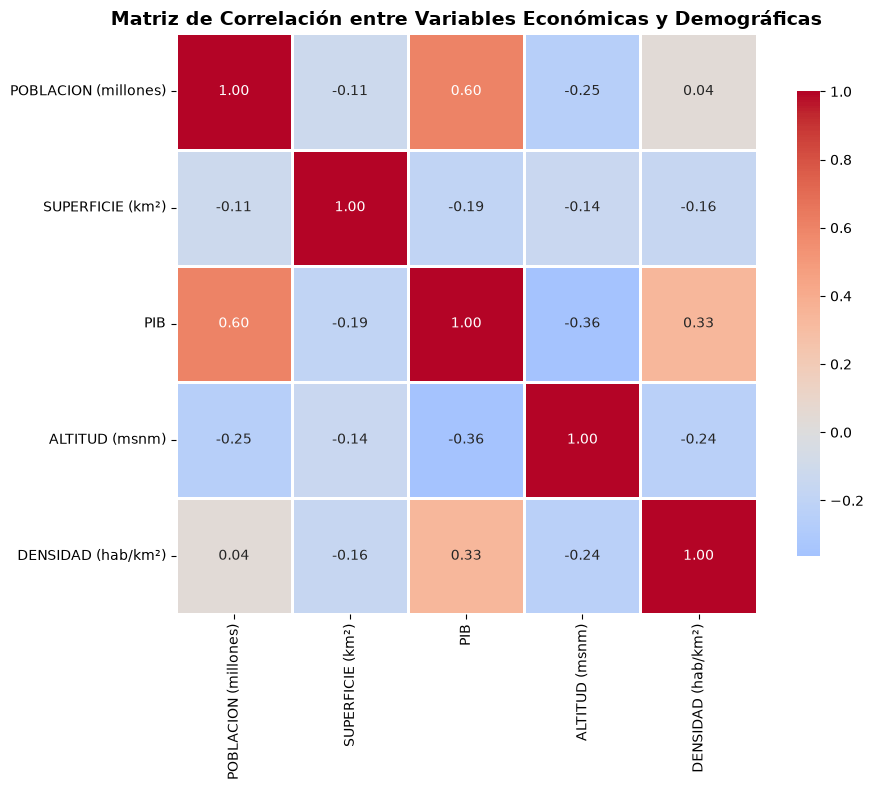

In [51]:
# 3. Gráfico de correlaciones (Heatmap)

# Seleccionar solo columnas numéricas relevantes
columnas_numericas = [
    "POBLACION (millones)",
    "SUPERFICIE (km²)",
    "PIB",
    "ALTITUD (msnm)",
    "DENSIDAD (hab/km²)",
]
correlaciones = peru_df[columnas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "Matriz de Correlación entre Variables Económicas y Demográficas",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

**📊 INTERPRETACIÓN DE RESULTADOS:**

- **Correlaciones positivas fuertes** (valores cercanos a +1): Indican que cuando una variable aumenta, la otra también tiende a aumentar
- **Correlaciones negativas fuertes** (valores cercanos a -1): Indican relación inversa entre variables
- **Correlaciones débiles** (valores cercanos a 0): Sugieren poca o ninguna relación lineal entre variables

**Relaciones clave esperadas:**
- **Población vs PIB**: Probablemente correlación positiva (más población = mayor actividad económica)
- **Población vs Densidad**: Correlación positiva esperada
- **Superficie vs Densidad**: Probablemente correlación negativa (mayor superficie = menor densidad si población es constante)
- **Altitud vs PIB**: Correlación débil o inexistente (como vimos en el análisis anterior)

**💡 COMUNICACIÓN DE HALLAZGOS:**

**1. Relaciones económico-demográficas:**
- La matriz revela qué factores están más relacionados con el desarrollo económico (PIB)
- Permite identificar si el tamaño poblacional, la densidad o la superficie son determinantes del PIB
- Ayuda a entender si departamentos grandes necesariamente tienen mayor economía

**2. Patrones territoriales:**
- La correlación entre superficie y densidad muestra cómo se distribuye la población en el territorio
- Departamentos extensos pueden tener baja densidad, indicando áreas despobladas o rurales
- Alta densidad sin alta población sugiere departamentos pequeños pero urbanizados

**3. Desarrollo vs geografía:**
- Si la altitud tiene baja correlación con PIB, confirma que la ubicación geográfica no determina el éxito económico
- Departamentos pueden prosperar independientemente de su altura sobre el nivel del mar
- Los recursos, políticas y conectividad son más importantes que la geografía física

**4. Eficiencia territorial:**
- La relación entre PIB y superficie indica si departamentos grandes aprovechan mejor su territorio
- Una correlación débil sugiere que el tamaño no garantiza desarrollo
- Departamentos pequeños pero bien gestionados pueden tener PIB similar a los grandes

**5. Implicaciones para políticas públicas:**
- **Si población y PIB están altamente correlacionados**: Las políticas deben enfocarse en centros poblados
- **Si densidad y PIB están correlacionados**: Urbanización y concentración pueden impulsar economía
- **Si superficie y PIB tienen baja correlación**: El desarrollo no requiere grandes extensiones territoriales
- **Si altitud no correlaciona con PIB**: Todas las regiones tienen potencial económico similar

### **GRÁFICO 4: PIB por Región Geográfica**

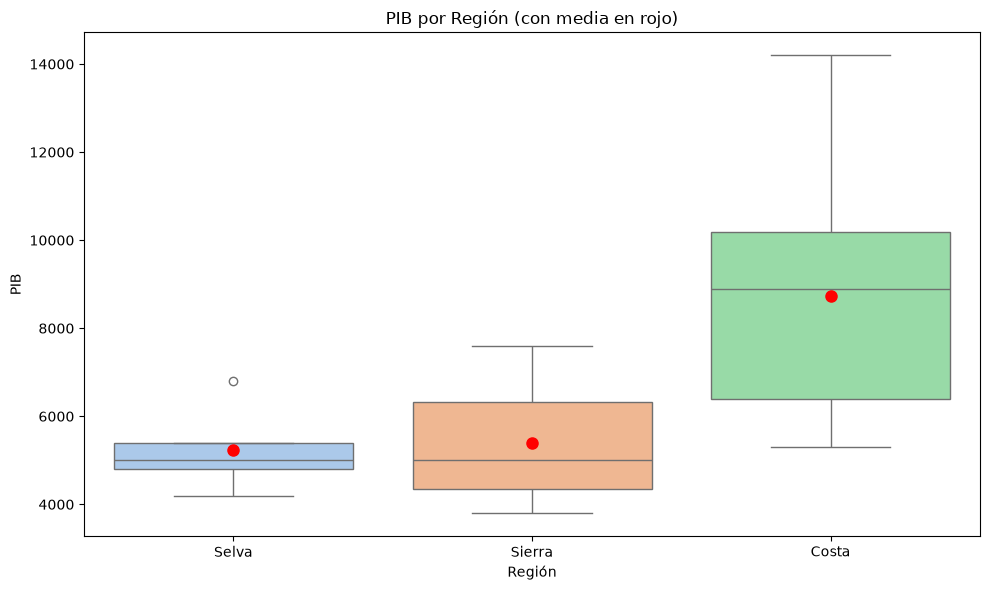

In [52]:
# 4. Diagrama de caja: PIB por región
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=peru_df,
    x="REGION",
    y="PIB",
    hue="REGION",
    palette="pastel",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": 8,
    },
)
plt.title("PIB por Región (con media en rojo)")
plt.xlabel("Región")
plt.ylabel("PIB")
plt.tight_layout()
plt.show()

**📊 INTERPRETACIÓN DE RESULTADOS:**
- El diagrama de caja permite comparar la distribución del PIB entre las tres regiones naturales
- Se observan diferencias en las medianas y rangos de PIB entre regiones
- Existen valores atípicos (outliers) que representan departamentos excepcionales en cada región
- La variabilidad dentro de cada región indica heterogeneidad económica

**💡 COMUNICACIÓN DE HALLAZGOS:**
- **Disparidad regional**: Las tres regiones naturales (Costa, Sierra, Selva) presentan diferentes niveles de desarrollo económico
- **Costa dominante**: Probablemente la región costera muestra mayor PIB promedio debido a puertos, industria y centros urbanos principales
- **Potencial no aprovechado**: La Sierra y Selva tienen recursos valiosos (minería, agricultura, biodiversidad) que podrían impulsar su economía
- **Heterogeneidad interna**: Dentro de cada región hay departamentos líderes y rezagados, lo que sugiere que las políticas deben ser específicas
- **Integración necesaria**: El desarrollo equilibrado requiere conectividad entre regiones y aprovechamiento de ventajas comparativas

### **GRÁFICO 5: Top 10 Departamentos por Población**

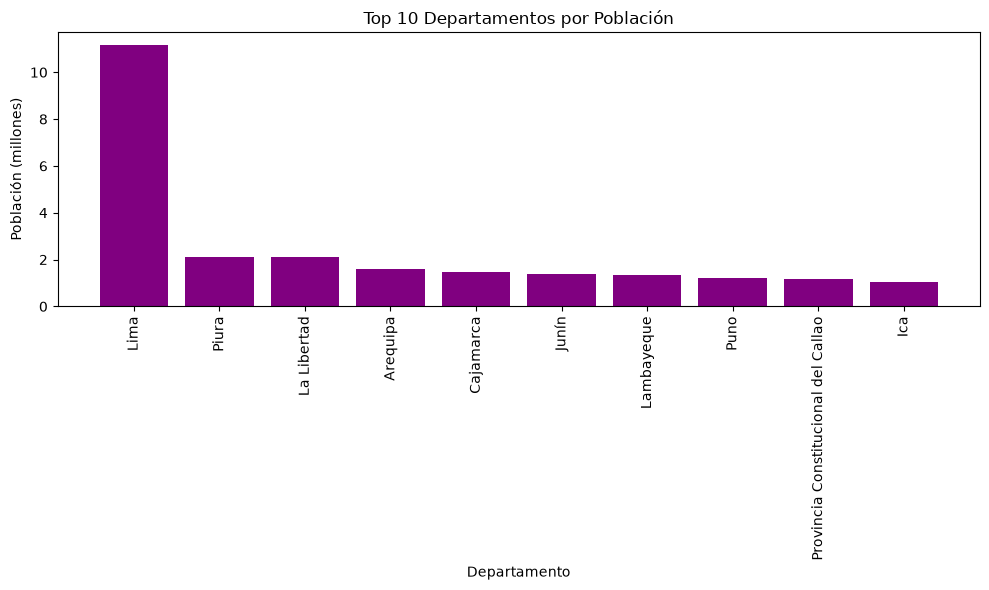

In [53]:
# 5. Gráfico de barras: Top 10 departamentos por población
top_10_pob = peru_df.nlargest(10, "POBLACION (millones)")
plt.figure(figsize=(10, 6))
plt.bar(top_10_pob["DEPARTAMENTO"], top_10_pob["POBLACION (millones)"], color="purple")
plt.title("Top 10 Departamentos por Población")
plt.xlabel("Departamento")
plt.ylabel("Población (millones)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**📊 INTERPRETACIÓN DE RESULTADOS:**
- Los 10 departamentos más poblados concentran un alto porcentaje de la población total
- Existe una diferencia marcada entre el departamento más poblado y el resto
- Los tres primeros lugares agrupan una proporción significativa de habitantes
- La distribución refleja el patrón de urbanización del país

**💡 COMUNICACIÓN DE HALLAZGOS:**
- **Macrocefalia urbana**: Lima y otros pocos departamentos concentran la mayoría de la población, generando presión sobre infraestructura y servicios
- **Atracción migratoria**: Los departamentos más poblados ofrecen mayores oportunidades laborales, educativas y de salud, atrayendo migrantes internos
- **Desafíos de gestión**: La alta concentración poblacional requiere inversión masiva en transporte, vivienda, agua, saneamiento y seguridad
- **Despoblamiento rural**: El crecimiento de centros urbanos contrasta con el despoblamiento de áreas rurales y departamentos periféricos
- **Planificación territorial**: Se necesita una estrategia nacional de ordenamiento territorial que promueva ciudades intermedias y desarrollo descentralizado

<div style="padding: 20px; background-color: #f1f2f6; border-radius: 10px; text-align: center; margin-top: 30px;">
    <p style="color: #2f3542; font-weight: 600;">Fin del Reporte</p>
    <p style="font-size: 0.9em; color: #57606f;">Generado con atención a la excelencia técnica.</p>
</div>